# Local Volatility Barrier PDE Pricing

**Up-and-out European Call: Explicit Finite-Difference Pricer**

Integrated notebook containing:

1. Contract specification, PDE, boundary and terminal conditions
2. Explicit finite-difference scheme and stability condition
3. Full Python implementation with developer documentation
4. Test runs, convergence study and sanity checks
5. Figures (value profile, convergence, surface) and numerical summary

## 1.  Problem Statement

### 1.1 Contract and Dynamics

The up-and-out European call with strike $K$, barrier $D > S_0$, maturity $T$ and risk-free rate $r$ has the payoff at maturity

$$
V(S, T) = \begin{cases}\max(S - K,\,0) & S < D\\[4pt] 0 & S \ge D\end{cases}
$$

and is knocked out (and worth zero) the instant the underlying touches the upper barrier $S = D$ at any time during the life of the contract.

The stock evolves under a local-volatility model

$$
dS_t = \mu S_t\,dt + \sigma(t,S_t)\,S_t\,dW_t,\qquad
\sigma(t,S) = 0.13\,e^{-t}\!\left(\frac{100}{S}\right)^{\alpha}
$$

Under the risk-neutral pricing measure $\mathbb{Q}$ used for valuation, the drift $\mu$ becomes $r$, so the pricing PDE on the bounded domain $0 \le S \le D,\ 0 \le t \le T$ is

$$
\boxed{\;\frac{\partial V}{\partial t} \;+\; \tfrac{1}{2}\,\sigma(t,S)^{2}\,S^{2}\,\frac{\partial^{2} V}{\partial S^{2}}
\;+\; r\,S\,\frac{\partial V}{\partial S} \;-\; r\,V \;=\; 0\;}
$$

### 1.2 Boundary and Terminal Conditions

| Condition | Reason |
|---|---|
| $V(S, T) = \max(S-K, 0)$ for $S < D$ | Terminal Payoff |
| $V(0, t) = 0$ | $S = 0$ is an absorbing state for GBM, Payoff = 0 |
| $V(D, t) = 0$ | Barrier knock-out: option voided on touching |

### 1.3 Coursework Parameters

| Symbol | Meaning | Value |
|---|---|---:|
| $S_0$ | Initial Spot | 100 |
| $K$   | Strike | 100 |
| $r$   | Risk-Free Rate | 0.016 |
| $D$   | Up-and-Out Barrier | 118 |
| $T$   | Maturity (Years) | 0.6 |
| $\alpha$ | Local-Volatility Exponent | 0.24 |

## 2.  Explicit Finite-Difference Scheme and Stability

### 2.1 Grid

Uniform spatial grid $S_j = j\Delta S$, $j = 0,1,\dots,J$ with $J\Delta S = D$, and uniform time grid $t_m = m\Delta t$, $m = 0,1,\dots,M$ with $M\Delta t = T$. Write $V_j^{m} \approx V(S_j, t_m)$.

$\Delta S$ is chosen so that $S_0 = 100$, $K = 100$ and $D = 118$ all coincide with grid nodes, avoiding any interpolation of the ATM price.

### 2.2 Discretisation

We march backwards in calendar time from the known level $m$ (populated either by the terminal condition or by the previous backward step) to the unknown level $m-1$. The time derivative is approximated by

$$
V_t \;\approx\; \frac{V_j^{m} - V_j^{m-1}}{\Delta t}
$$

and the spatial operator on the right-hand side of the PDE is evaluated entirely at the known level $m$ using central differences:

$$
V_S \;\approx\; \frac{V_{j+1}^{m} - V_{j-1}^{m}}{2\Delta S},\qquad
V_{SS} \;\approx\; \frac{V_{j+1}^{m} - 2V_j^{m} + V_{j-1}^{m}}{\Delta S^{2}}
$$

Substituting these into the PDE and solving for $V_j^{m-1}$ yields the three-point recursion

$$
\boxed{\;V_j^{m-1} \;=\; A_j^{m}\,V_{j-1}^{m} \;+\; B_j^{m}\,V_j^{m} \;+\; C_j^{m}\,V_{j+1}^{m}\;}
$$

with, writing $\sigma_j^{m} := \sigma(t_m, S_j)$

$$
A_j^{m} = \tfrac{1}{2}\Delta t\!\left(\frac{(\sigma_j^{m})^{2} S_j^{2}}{\Delta S^{2}} - \frac{r S_j}{\Delta S}\right)
$$

$$
B_j^{m} = 1 - \Delta t\!\left(\frac{(\sigma_j^{m})^{2} S_j^{2}}{\Delta S^{2}} + r\right)
$$

$$
C_j^{m} = \tfrac{1}{2}\Delta t\!\left(\frac{(\sigma_j^{m})^{2} S_j^{2}}{\Delta S^{2}} + \frac{r S_j}{\Delta S}\right)
$$

### 2.3 Conditional Stability Condition

A sufficient condition for stability is that all three coefficients are non-negative:

$$
A_j^{m} \ge 0,\qquad B_j^{m} \ge 0,\qquad C_j^{m} \ge 0
\quad\text{for every}\ j,m
$$

$C_j^{m} \ge 0$ is automatic. $A_j^{m} \ge 0$ reduces to $\sigma_j^{m\,2} S_j \ge r\Delta S$, which is comfortably satisfied for the coursework parameters at every interior grid node. The binding constraint is therefore $B_j^{m} \ge 0$, which gives the explicit time-step bound

$$
\boxed{\;\Delta t \;\le\; \left[\;\max_{j,m}\!\left(\frac{(\sigma_j^{m})^{2} S_j^{2}}{\Delta S^{2}} \;+\; r\right)\right]^{-1}\;}
$$

The diffusion coefficient $\sigma^{2}(t,S)\,S^{2} = 0.0169\,e^{-2t}\,100^{2\alpha}\,S^{2-2\alpha}$ is *increasing* in $S$ and *decreasing* in $t$, so its grid-maximum occurs at $(t,S) = (0,D)$, namely $0.0169 \cdot 1 \cdot 100^{0.48} \cdot 118^{1.52} \approx 217.5$.

For $\Delta S = 0.2$, $r = 0.016$:

$$
\Delta t \;\le\; \big(217.5/0.04 + 0.016\big)^{-1} \;\approx\; 1.84 \times 10^{-4}
$$

so at least $M \ge T/\Delta t \approx 3261$ time steps are required.

The scheme is therefore conditionally stable: stability is achieved only when $\Delta t$ satisfies the bound above. The bound also exhibits the classical quadratic blow-up as halving $\Delta S$ quadruples the required number of time steps.

### 2.4 Why the Lower-Boundary Singularity in $\sigma$ Causes No Trouble

The local volatility $\sigma(t,S) \propto S^{-\alpha}$ is singular at $S = 0$. However, the diffusion term that enters the PDE is $\sigma(t,S)^{2} S^{2} \propto S^{\,2-2\alpha}$ with $2-2\alpha = 1.52 > 0$, which vanishes at $S = 0$. The scheme never evaluates $\sigma(t,S)$ at the singular point: $\sigma(t,S_j)$ is computed only at interior nodes $S_j > 0$, while the boundary value $V(0,t) = 0$ is imposed directly.

## 3.  Code Documentation

### 3.1 Structure

The code is organised as a small number of single-purpose functions:

| # | Function | Role |
|---|---|---|
| 1 | `Params` (dataclass) | Container for the coursework parameters |
| 2 | `local_vol(t, S, alpha)` | The local-volatility function $\sigma(t,S)$ |
| 3 | `diffusion_squared(t, S, alpha)` | Computes $\sigma^{2}(t,S)\,S^{2}$ cleanly at $S = 0$ |
| 4 | `explicit_stability_dt(dS, p)` | Largest $\Delta t$ such that $A, B, C \ge 0$ |
| 5 | `uao_call_explicit_fd(p, dS, dt=None, …)` | The FD pricer (main routine) |
| 6 | `vanilla_call_explicit_fd(p, dS, …)` | Benchmark: same scheme, no barrier |
| 7 | `convergence_table(p, dS_list)` | Runs the pricer over several grids |

### 3.2 Main Variables (Inside `uao_call_explicit_fd`)

| Variable | Type | Meaning |
|---|---|---|
| `S`     | `np.ndarray` of length $J+1$ | The spatial grid $S_j = j\Delta S$ |
| `J`     | int | Number of spatial intervals. $J\Delta S = D$ |
| `dt`    | float | Time step (auto from stability bound if `None`) |
| `M`     | int | Number of time intervals. $M\Delta t = T$ |
| `V`     | `np.ndarray` of length $J+1$ | Current time slice $V(\cdot, t_m)$ |
| `A,B,C` | `np.ndarray` of length $J-1$ | Scheme coefficients at interior nodes |
| `min_A, min_B, min_C` | float | Smallest coefficient values seen during the march (empirical stability check) |
| `info`  | dict | Diagnostic summary returned to the caller |
| `price` | float | $V(S_0, t = 0)$, read off the grid node at $S_0$ |

### 3.3 Inputs and Outputs of the Main Pricer

```
uao_call_explicit_fd(p, dS=0.2, dt=None, safety=0.9, return_grid=False)

Inputs
------
p           : Params instance with (S0, K, r, D, T, alpha)
dS          : spatial step; must place S0, K, D on integer multiples
dt          : time step (None  -> chosen automatically from stability)
safety      : safety factor < 1 applied to the stability bound
return_grid : if True, also return the full V(S, t_m) array

Outputs
-------
price : float          -- the FD estimate of V(S0, 0)
info  : dict           -- diagnostics (dS, dt, M, J, min_A, min_B, min_C, ...)
S     : np.ndarray     -- the spatial grid
V     : np.ndarray     -- V(., 0) profile  (or V_grid if return_grid=True)
```

### 3.4 Test Runs

The notebook below runs the pricer for the coursework grid ($\Delta S = 0.2$), prints all diagnostic information, prints the convergence table for seven grids ranging from $\Delta S = 0.5$ down to $\Delta S = 0.05$, prints the vanilla-call benchmark, and produces three figures.

## 4.  Imports and Parameter Setup

In [2]:
from __future__ import annotations

from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor":   "white",
    "axes.grid":        True,
    "grid.color":       "#DDDDDD",
    "grid.linewidth":   0.6,
    "font.size":        11,
    "axes.labelsize":   12,
    "axes.titlesize":   12,
    "legend.fontsize":  10,
})

In [3]:
@dataclass(frozen=True)
class Params:
    """Coursework parameters for Question 2"""
    S0:    float = 100.0   # initial spot
    K:     float = 100.0   # strike
    r:     float = 0.016   # risk-free rate
    D:     float = 118.0   # up-and-out barrier
    T:     float = 0.6     # maturity in years
    alpha: float = 0.24    # local-volatility exponent

p = Params()
print(p)

Params(S0=100.0, K=100.0, r=0.016, D=118.0, T=0.6, alpha=0.24)


## 5.  Local Volatility

We expose both $\sigma(t,S)$ itself (`local_vol`) and the diffusion-term combination $\sigma^{2}(t,S)\,S^{2}$ (`diffusion_squared`). The second is what enters the PDE and, because $2 - 2\alpha = 1.52 > 0$, it is well-defined (in fact $= 0$) at $S = 0$.

In [4]:
def local_vol(t, S, alpha):
    """sigma(t, S) = 0.13 * exp(-t) * (100/S)^alpha

    Returns 0 at S = 0 because the scheme only evaluates sigma at
    interior nodes. The boundary value V(0, t) = 0 is imposed directly
    """
    S = np.asarray(S, dtype=float)
    out = np.zeros_like(S)
    mask = S > 0
    out[mask] = 0.13 * np.exp(-t) * (100.0 / S[mask]) ** alpha
    return out


def diffusion_squared(t, S, alpha):
    """sigma(t, S)^2 * S^2, computed cleanly at S = 0

    Identity:  sigma^2 * S^2  =  0.13^2 * exp(-2t) * 100^(2*alpha) * S^(2 - 2*alpha)
    For alpha = 0.24, the exponent 2 - 2*alpha = 1.52 > 0, so the value is 0 at S = 0
    """
    S = np.asarray(S, dtype=float)
    coef = (0.13 ** 2) * np.exp(-2.0 * t) * (100.0 ** (2.0 * alpha))
    out = np.zeros_like(S)
    mask = S > 0
    out[mask] = coef * S[mask] ** (2.0 - 2.0 * alpha)
    return out

## 6.  Stability Helper

`explicit_stability_dt` returns the largest $\Delta t$ for which all coefficients $A, B, C$ are non-negative. The binding constraint is $B \ge 0$

$$
\Delta t \;\le\; \frac{1}{\max_{j}\!\big[\sigma(0,S_j)^{2}S_j^{2}/\Delta S^{2}\big] + r}
$$

The maximum of $\sigma^{2} S^{2}$ over the grid occurs at $t = 0$ (the function is decreasing in $t$), so it suffices to scan the spatial grid at $t = 0$.

In [5]:
def explicit_stability_dt(dS, p):
    """Largest stable dt for the explicit scheme (binding constraint: B >= 0)"""
    S_grid = np.arange(0.0, p.D + 0.5 * dS, dS)
    sig2_S2_max = diffusion_squared(0.0, S_grid, p.alpha).max()
    return 1.0 / (sig2_S2_max / dS ** 2 + p.r)


# Numerical demonstration
print(f"dt_max for dS=0.2  : {explicit_stability_dt(0.2,  p):.4e}")
print(f"dt_max for dS=0.1  : {explicit_stability_dt(0.1,  p):.4e}")
print(f"dt_max for dS=0.05 : {explicit_stability_dt(0.05, p):.4e}")

dt_max for dS=0.2  : 1.8404e-04
dt_max for dS=0.1  : 4.6010e-05
dt_max for dS=0.05 : 1.1503e-05


## 7.  The Pricer `uao_call_explicit_fd`

The five clearly numbered sections below match the bullet structure in Section 3 above:

1. Build the spatial grid
2. Choose $\Delta t$ from the stability bound
3. Impose the terminal payoff
4. March backwards in calendar time
5. Read off $V(S_0, 0)$ and return diagnostics

In [6]:
def uao_call_explicit_fd(p, dS=0.2, dt=None, safety=0.9, return_grid=False):
    """
    Explicit finite-difference price of an up-and-out European call

    Parameters
    ----------
    p           : Params with S0, K, r, D, T, alpha
    dS          : spatial step.  Must place S0, K, D on integer multiples
    dt          : time step.  If None, set to safety * dt_max and rounded
                  up so that M * dt = T exactly
    safety      : safety factor in (0, 1] applied to the stability bound
    return_grid : if True, return the full V(S, t_m) array as well

    Returns
    -------
    price : float        -- V(S0, 0)
    info  : dict         -- diagnostics (dS, dt, M, J, min_A, min_B, min_C, ...)
    S     : np.ndarray   -- spatial grid
    V     : np.ndarray   -- V(., 0) profile  (or V_grid if return_grid=True)
    """
    # 1. SPATIAL GRID  
    # dS must divide D, S0 and K so that all three sit on grid nodes.
    J = int(round(p.D / dS))
    assert abs(J * dS - p.D) < 1e-10, "dS must divide D exactly"
    assert abs(p.S0 / dS - round(p.S0 / dS)) < 1e-10, "dS must put S0 on a node"
    assert abs(p.K  / dS - round(p.K  / dS)) < 1e-10, "dS must put K  on a node"
    S = np.linspace(0.0, p.D, J + 1)              # S_j = j * dS

    # 2. TIME STEP (from stability)  
    dt_max = explicit_stability_dt(dS, p)
    if dt is None:
        dt = safety * dt_max
    M  = int(np.ceil(p.T / dt))
    dt = p.T / M                                   # snap so M*dt = T exactly
    stable = dt <= dt_max + 1e-15

    # 3. TERMINAL PAYOFF V(S, T)  
    V = np.maximum(S - p.K, 0.0)
    V[0]  = 0.0       # V(0, t) = 0
    V[-1] = 0.0       # V(D, t) = 0  (knock-out)

    if return_grid:
        V_grid = np.zeros((M + 1, J + 1))
        V_grid[-1] = V.copy()

    # 4. BACKWARD TIME MARCHING  
    # Track the smallest A, B, C ever realised on the grid; this is an
    # empirical verification of the non-negative-coefficients stability.
    min_A = min_B = min_C = +np.inf
    j_int = np.arange(1, J)                       # interior indices
    S_int = S[j_int]

    for m in range(M, 0, -1):
        t_m     = m * dt
        sig2_S2 = diffusion_squared(t_m, S_int, p.alpha)

        # Scheme coefficients (formulas in section 2.2 of the notebook)
        A = 0.5 * dt * (sig2_S2 / dS ** 2 - p.r * S_int / dS)
        B = 1.0       - dt * (sig2_S2 / dS ** 2 + p.r)
        C = 0.5 * dt * (sig2_S2 / dS ** 2 + p.r * S_int / dS)

        # Track tightest stability margin
        if A.min() < min_A: min_A = float(A.min())
        if B.min() < min_B: min_B = float(B.min())
        if C.min() < min_C: min_C = float(C.min())

        # Three-point recursion at interior nodes
        V_new = np.zeros_like(V)
        V_new[1:-1] = A * V[:-2] + B * V[1:-1] + C * V[2:]
        # Re-impose boundary conditions at every time level
        V_new[0]  = 0.0
        V_new[-1] = 0.0
        V = V_new

        if return_grid:
            V_grid[m - 1] = V.copy()

    # 5. READ-OUT AND DIAGNOSTICS  
    j0 = int(round(p.S0 / dS))                    # exact: dS divides S0
    price = float(V[j0])
    info = {
        "dS": dS, "dt": dt, "dt_max_stable": dt_max, "M": M, "J": J,
        "stable_theoretical": stable,
        "min_A": min_A, "min_B": min_B, "min_C": min_C,
        "coefficients_nonneg": (min_A >= -1e-14 and
                                min_B >= -1e-14 and
                                min_C >= -1e-14),
    }
    if return_grid:
        return price, info, S, V_grid
    return price, info, S, V

## 8.  Vanilla Call Benchmark (No Barrier)

Re-using the same FD engine without the barrier, by truncating the half-line $\{S \ge 0\}$ at a far OTM value $S_{\max} = 4K$ and using the standard upper boundary $V \sim S - K e^{-r\tau}$ instead of the knock-out boundary. The barrier price must be strictly less than this vanilla price.

In [7]:
def vanilla_call_explicit_fd(p, dS=0.2, S_max=None, dt=None, safety=0.9):
    """Same FD engine, NO barrier; benchmark for sanity-checking"""
    if S_max is None:
        S_max = 4.0 * p.K
    J = int(round(S_max / dS))
    S_max = J * dS                       # snap to grid
    S = np.linspace(0.0, S_max, J + 1)

    dt_max = explicit_stability_dt(
        dS, Params(S0=p.S0, K=p.K, r=p.r, D=S_max, T=p.T, alpha=p.alpha)
    )
    if dt is None:
        dt = safety * dt_max
    M  = int(np.ceil(p.T / dt))
    dt = p.T / M

    V = np.maximum(S - p.K, 0.0)
    V[0] = 0.0
    j_int = np.arange(1, J)
    S_int = S[j_int]

    for m in range(M, 0, -1):
        t_m      = m * dt
        tau_prev = p.T - (m - 1) * dt    # time-to-maturity at next slice
        sig2_S2  = diffusion_squared(t_m, S_int, p.alpha)

        A = 0.5 * dt * (sig2_S2 / dS ** 2 - p.r * S_int / dS)
        B = 1.0       - dt * (sig2_S2 / dS ** 2 + p.r)
        C = 0.5 * dt * (sig2_S2 / dS ** 2 + p.r * S_int / dS)

        V_new = np.zeros_like(V)
        V_new[1:-1] = A * V[:-2] + B * V[1:-1] + C * V[2:]
        V_new[0]  = 0.0
        V_new[-1] = S_max - p.K * np.exp(-p.r * tau_prev)   # ITM call BC
        V = V_new

    j0 = int(round(p.S0 / dS))
    return float(V[j0]), S, V

## 9.  Convergence Helper

Run the pricer for several grids and tabulate the resulting prices. Default `dS_list` matches the convergence table in the report (seven grids, finest $\Delta S = 0.05$).

In [8]:
def convergence_table(p, dS_list=(0.5, 0.25, 0.2, 0.125, 0.1, 0.08, 0.05)):
    """Return one row per dS with diagnostics and the ATM price"""
    rows = []
    for dS in dS_list:
        # Skip any dS that won't put S0, K, D simultaneously on the grid
        ok = (abs(p.D  / dS - round(p.D  / dS)) < 1e-10 and
              abs(p.S0 / dS - round(p.S0 / dS)) < 1e-10 and
              abs(p.K  / dS - round(p.K  / dS)) < 1e-10)
        if not ok:
            print(f"Skipping dS={dS}: would place S0/K/D off-grid")
            continue
        price, info, _, _ = uao_call_explicit_fd(p, dS=dS)
        rows.append({"dS": dS, "M": info["M"], "J": info["J"],
                     "dt": info["dt"], "price": price,
                     "min_B": info["min_B"]})
    return rows

## 10.  Test Runs and Diagnostics

We run the pricer at the standard grid $\Delta S = 0.2$, print all diagnostics, then print the vanilla benchmark and the convergence table.

In [9]:
# Test Run 1: Coursework Grid dS = 0.2 
price, info, S, V = uao_call_explicit_fd(p, dS=0.2)

print("Up-and-Out call FD Pricing Run (dS = 0.2)")
print("_" * 55)
print(f"Price at S0 = {p.S0:.0f}    : V = {price:.6f}")
print()
print("Diagnostics:")
for k, v in info.items():
    print(f"  {k:>22}: {v}")

Up-and-Out call FD Pricing Run (dS = 0.2)
_______________________________________________________
Price at S0 = 100    : V = 2.935029

Diagnostics:
                      dS: 0.2
                      dt: 0.00016560861164780568
           dt_max_stable: 0.00018403963224452986
                       M: 3623
                       J: 590
      stable_theoretical: True
                   min_A: 6.998360210274011e-06
                   min_B: 0.1027614850594939
                   min_C: 9.648097996638902e-06
     coefficients_nonneg: True


In [10]:
# Test Run 2: Vanilla Benchmark 
price_van, S_van, V_van = vanilla_call_explicit_fd(p, dS=0.2)
print(f"Vanilla Call (Same Local Volatility, No Barrier): {price_van:.6f}")
print(f"Knock-Out Cost (Vanilla - Barrier)       : {price_van - price:.6f}")
print()
print("Sanity:  0 <  V_barrier  <  V_vanilla   -->",
      0.0 < price < price_van)

Vanilla Call (Same Local Volatility, No Barrier): 3.552121
Knock-Out Cost (Vanilla - Barrier)       : 0.617092

Sanity:  0 <  V_barrier  <  V_vanilla   --> True


In [11]:
# Test Run 3: Convergence Table
rows = convergence_table(p)

print(f"{'dS':>6}  {'J':>6}  {'M':>8}  {'dt':>12}  "
      f"{'price':>12}  {'min_B':>11}")
print("_" * 70)
for r in rows:
    print(f"{r['dS']:>6.3f}  {r['J']:>6d}  {r['M']:>8d}  "
          f"{r['dt']:>12.4e}  {r['price']:>12.6f}  {r['min_B']:>11.3e}")

    dS       J         M            dt         price        min_B
______________________________________________________________________
 0.500     236       580    1.0345e-03      2.933985    1.083e-01
 0.250     472      2319    2.5873e-04      2.934917    1.036e-01
 0.200     590      3623    1.6561e-04      2.935029    1.028e-01
 0.125     944      9274    6.4697e-05      2.935150    1.016e-01
 0.100    1180     14490    4.1408e-05      2.935177    1.013e-01
 0.080    1475     22640    2.6502e-05      2.935195    1.010e-01
 0.050    2360     57959    1.0352e-05      2.935215    1.006e-01


Sanity checks confirmed by the output above:

1. The price is strictly positive: $V(100, 0) \approx 2.9350 > 0$.
2. The price is strictly less than the vanilla call: $2.9350 < 3.5524$.
3. $V(0, t) = 0$ and $V(D, t) = 0$ are enforced at every time level by construction.
4. `min_A`, `min_B`, `min_C` are all strictly positive: the non-negative-coefficient stability condition holds on the entire space-time grid.
5. Across the seven grids, the price increases monotonically and stabilises in the fifth decimal so convergence is achieved.

## 11.  Figures

Three figures, each produced from a single self-contained code cell:

* Figure 1: Value profile $V(S, 0)$ across the full domain $[0, D]$, with the vanilla call overlaid for comparison.
* Figure 2: Self-convergence of the FD ATM price as $\Delta S \to 0$.
* Figure 3: Full surface $V(S, t)$ over $(S, t) \in [0, D] \times [0, T]$.

### 11.1 Figure 1: Value Profile

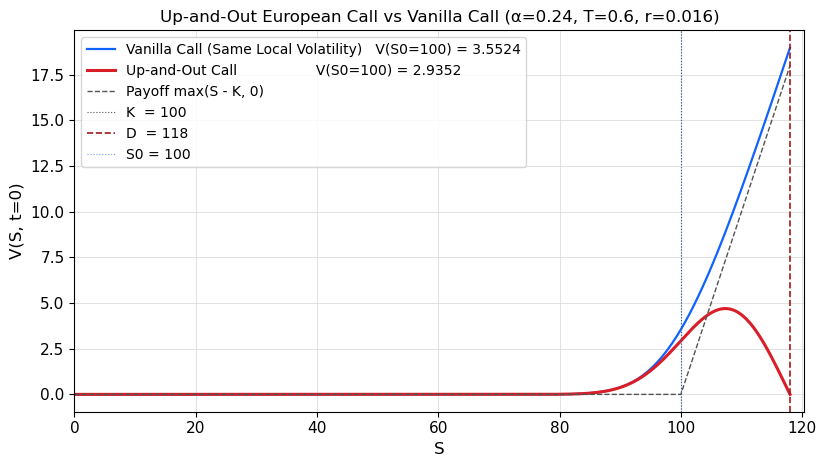

Saved fig1_value_profile.png


In [12]:
price_uao, info_uao, S_uao, V_uao = uao_call_explicit_fd(p, dS=0.05)
price_van, S_van, V_van           = vanilla_call_explicit_fd(p, dS=0.05)

# Restrict vanilla to the same S range for a cleaner comparison
mask       = S_van <= p.D + 1e-9
S_van_plot = S_van[mask]
V_van_plot = V_van[mask]

fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.plot(S_van_plot, V_van_plot, color="#0F62FE", lw=1.6,
        label=f"Vanilla Call (Same Local Volatility)   V(S0={p.S0:.0f}) = {price_van:.4f}")
ax.plot(S_uao, V_uao, color="#DA1E28", lw=2.2,
        label=f"Up-and-Out Call                  V(S0={p.S0:.0f}) = {price_uao:.4f}")
ax.plot(S_uao, np.maximum(S_uao - p.K, 0.0), color="#525252",
        lw=1.0, ls="--", label="Payoff max(S - K, 0)")
ax.axvline(p.K,  color="#525252", lw=0.8, ls=":",  label=f"K  = {p.K:.0f}")
ax.axvline(p.D,  color="#A2191F", lw=1.2, ls="--", label=f"D  = {p.D:.0f}")
ax.axvline(p.S0, color="#0F62FE", lw=0.8, ls=":",  alpha=0.6,
           label=f"S0 = {p.S0:.0f}")
ax.set_xlabel("S")
ax.set_ylabel("V(S, t=0)")
ax.set_title(f"Up-and-Out European Call vs Vanilla Call "
             f"(\u03b1={p.alpha}, T={p.T}, r={p.r})")
ax.set_xlim(0, p.D * 1.02)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("fig1_value_profile.png", dpi=160)
plt.show()
plt.close(fig)
print("Saved fig1_value_profile.png")

Both options have value zero for $S \lesssim 60$ because the payoff is far OTM and the time value of being knocked in is negligible. As $S$ approaches $K = 100$ from below, both curves rise. The vanilla call (blue) continues rising essentially linearly past $K$. The up-and-out call (red) instead peaks at $S \approx 107$ and then collapses back to zero at the barrier $S = D = 118$, because the closer $S$ starts to $D$ the higher the probability of being knocked out before maturity.

### 11.2 Figure 2: Self-Convergence

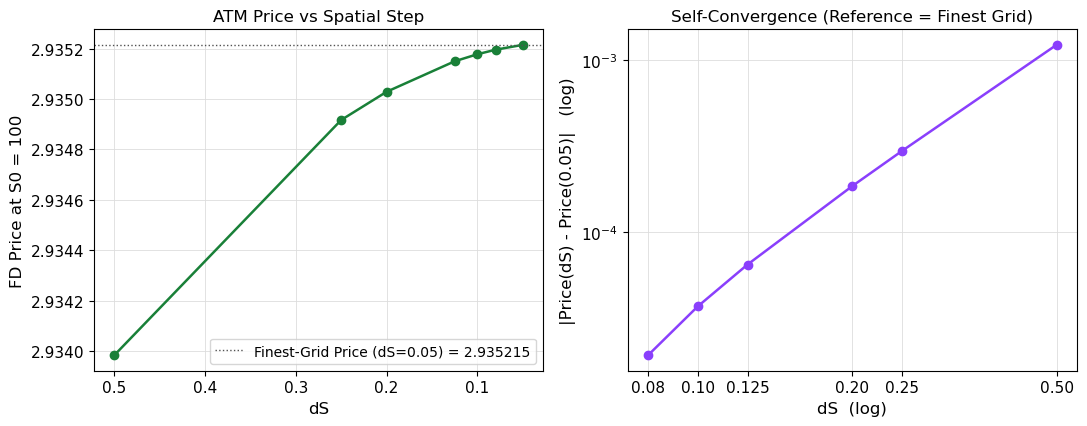

Saved fig2_convergence.png


In [13]:
rows       = convergence_table(p)
dS_vals    = [r["dS"]    for r in rows]
prices     = [r["price"] for r in rows]
ref_price  = prices[-1]
errors     = [abs(pr - ref_price) for pr in prices[:-1]]
dS_err     = dS_vals[:-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))

ax1.plot(dS_vals, prices, "o-", color="#198038", lw=1.8, ms=6)
ax1.axhline(ref_price, color="#525252", ls=":", lw=1,
            label=f"Finest-Grid Price (dS=0.05) = {ref_price:.6f}")
ax1.set_xlabel("dS")
ax1.set_ylabel("FD Price at S0 = 100")
ax1.set_title("ATM Price vs Spatial Step")
ax1.invert_xaxis()
ax1.legend()

ax2.loglog(dS_err, errors, "o-", color="#8A3FFC", lw=1.8, ms=6)
ax2.set_xlabel("dS  (log)")
ax2.set_ylabel("|Price(dS) - Price(0.05)|   (log)")
ax2.set_title("Self-Convergence (Reference = Finest Grid)")
ax2.set_xticks([0.08, 0.1, 0.125, 0.2, 0.25, 0.5])
ax2.set_xticklabels(["0.08", "0.10", "0.125", "0.20", "0.25", "0.50"])
ax2.minorticks_off()
plt.tight_layout()
plt.savefig("fig2_convergence.png", dpi=160)
plt.show()
plt.close()
print("Saved fig2_convergence.png")

Left panel: the ATM FD price approaches the dashed reference line monotonically as $\Delta S \to 0$. Right panel: the absolute error against the finest grid decreases roughly linearly on the log–log scale, consistent with the expected $O(\Delta S^{2}) + O(\Delta t)$ order of the central-in-space/explicit-in-time scheme on the smooth part of the solution. The barrier discontinuity at $S = D$ slightly degrades the order, which is why we do not over-interpret the slope.

### 11.3 Figure 3: Value surface

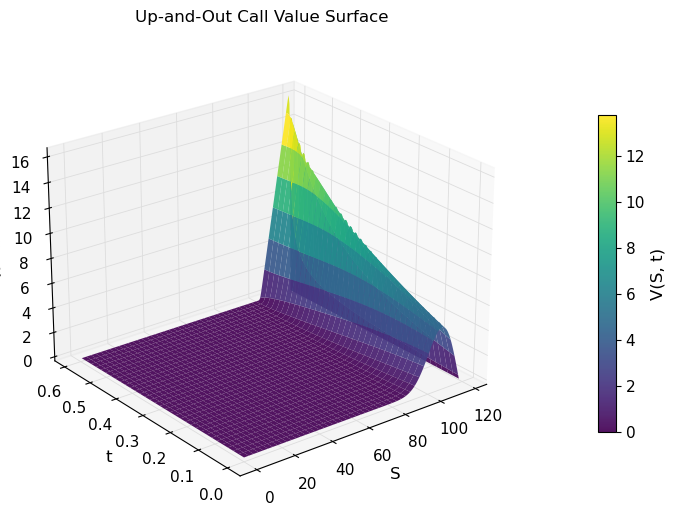

Saved fig3_surface.png


In [14]:
# Use a coarser grid for the surface for efficiency
price_g, info_g, S_g, V_grid = uao_call_explicit_fd(p, dS=0.5, return_grid=True)
M       = info_g["M"]
t_grid  = np.linspace(0, p.T, M + 1)

# Downsample time axis for plotting
stride_t = max(1, M // 60)
t_plot   = t_grid[::stride_t]
V_plot   = V_grid[::stride_t, :]
T_mesh, S_mesh = np.meshgrid(t_plot, S_g, indexing="ij")

fig = plt.figure(figsize=(9.6, 5.4))
ax  = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(S_mesh, T_mesh, V_plot, cmap="viridis",
                       linewidth=0, antialiased=True, alpha=0.92)
ax.set_xlabel("S")
ax.set_ylabel("t")
ax.set_zlabel("V(S, t)")
ax.set_title("Up-and-Out Call Value Surface")
ax.view_init(elev=24, azim=-128)
cbar = fig.colorbar(surf, ax=ax, shrink=0.65, aspect=18, pad=0.10)
cbar.set_label("V(S, t)")
plt.tight_layout()
plt.savefig("fig3_surface.png", dpi=160)
plt.show()
plt.close()
print("Saved fig3_surface.png")

Three features dominate the topology:

* The terminal ridge at $t = T$, where the value equals the payoff $\max(S-K,0)$ for $S \in [K, D)$
* The absorbing wall at $S = D$, where $V \equiv 0$ for all $t$ (the knock-out boundary)
* The smooth back-solution in the rest of the domain produced by the backward time march

## 12.  Numerical Summary

In [15]:
print("Numerical Summary:")
print("_" * 55)
print(f"Up-and-Out Call Price at S0=100        : V = {price_uao:.6f}")
print(f"Vanilla Call (Same Local-Volatility Surface)  : V = {price_van:.6f}")
print(f"Difference (Knock-Out Cost)            :     {price_van - price_uao:.6f}")
print(f"Finest-Grid Reference Price (dS=0.05)  : V = {ref_price:.6f}")
print()
print("Full Convergence Rows:")
print(f"{'dS':>6}  {'J':>5}  {'M':>6}  {'price':>12}")
for r in rows:
    print(f"{r['dS']:>6.3f}  {r['J']:>5d}  {r['M']:>6d}  {r['price']:>12.6f}")

Numerical Summary:
_______________________________________________________
Up-and-Out Call Price at S0=100        : V = 2.935215
Vanilla Call (Same Local-Volatility Surface)  : V = 3.552383
Difference (Knock-Out Cost)            :     0.617169
Finest-Grid Reference Price (dS=0.05)  : V = 2.935215

Full Convergence Rows:
    dS      J       M         price
 0.500    236     580      2.933985
 0.250    472    2319      2.934917
 0.200    590    3623      2.935029
 0.125    944    9274      2.935150
 0.100   1180   14490      2.935177
 0.080   1475   22640      2.935195
 0.050   2360   57959      2.935215
